In [1]:
# 0. Setup and load the Iris dataset
# If needed, install packages in a notebook cell with:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score
)
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = "iris.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/mnt/data/iris.csv"):
    DATA_PATH = "/mnt/data/iris.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# This notebook expects four numeric measurement columns and one species/label column.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

# If your column names differ, edit feature_cols and target_col above.
X = df[feature_cols].copy()
y = df[target_col].astype(str).copy()

print("\nSpecies counts:")
print(y.value_counts())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Condition: petal_length > 4.5 cm
Number of flowers satisfying condition: 63

Species counts within the condition:


,Count
species,
virginica,49
versicolor,14


,Conditional Probability
species,
setosa,0.000000
versicolor,0.222222
virginica,0.777778



Probability sum: 1.0


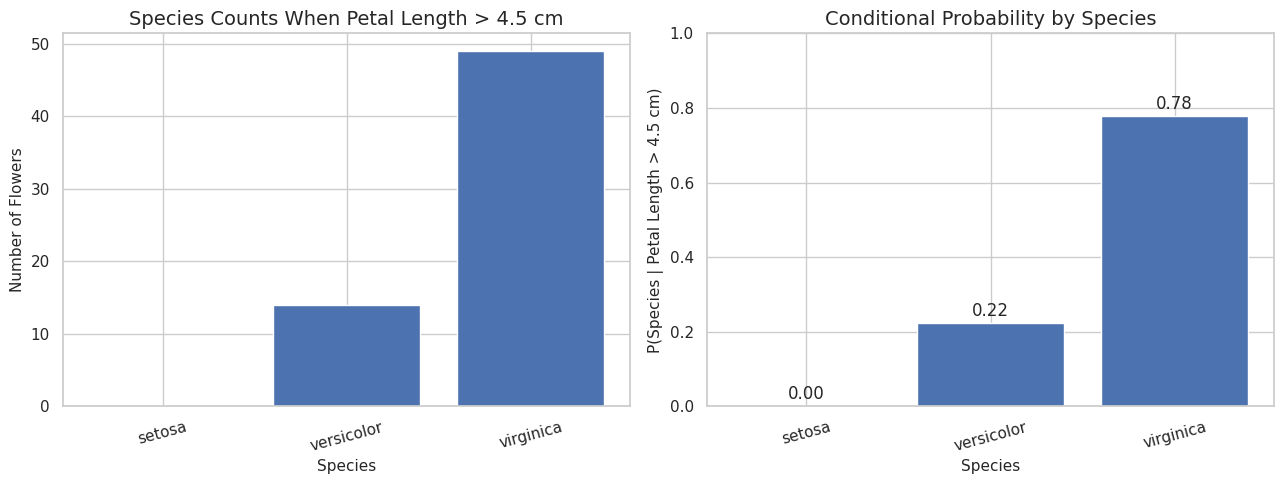

In [6]:
# 5. Conditional Probability
condition = df["petal_length"] > 4.5
condition_df = df.loc[condition]

print("Condition: petal_length > 4.5 cm")
print("Number of flowers satisfying condition:", len(condition_df))
print("\nSpecies counts within the condition:")
display(condition_df[target_col].value_counts().rename("Count").to_frame())

if len(condition_df) == 0:
    print("No rows satisfy this condition. Try changing the threshold.")
else:
    probabilities = (
        condition_df[target_col].value_counts(normalize=True)
        .reindex(labels, fill_value=0)
        .rename("Conditional Probability")
    )
    display(probabilities.to_frame())
    print("\nProbability sum:", round(probabilities.sum(), 4))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    counts = condition_df[target_col].value_counts().reindex(labels, fill_value=0)
    axes[0].bar(counts.index, counts.values)
    axes[0].set(title="Species Counts When Petal Length > 4.5 cm",
                xlabel="Species", ylabel="Number of Flowers")
    axes[0].tick_params(axis="x", rotation=15)

    axes[1].bar(probabilities.index, probabilities.values)
    axes[1].set(title="Conditional Probability by Species",
                xlabel="Species", ylabel="P(Species | Petal Length > 4.5 cm)", ylim=(0, 1))
    axes[1].tick_params(axis="x", rotation=15)
    for i, v in enumerate(probabilities.values):
        axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
    plt.tight_layout()
    plt.show()
